# 26 · Shape Descriptors and Their Limits

LRT4012 Robot Vision · Fall 2026


## Boundaries, regions and shape measurements

Contours are ordered boundary point sequences. `RETR_EXTERNAL` returns outer boundaries; `RETR_TREE` also reports nested contours. `CHAIN_APPROX_SIMPLE` compresses straight boundary runs. Binary-mask quality determines the measured shape.

$$m_{pq}=\sum_{x,y}x^p y^q B(x,y),\qquad c_x=m_{10}/m_{00},\quad c_y=m_{01}/m_{00}.$$

$B$ is a binary region, $(x,y)$ are pixel coordinates, $p,q$ are nonnegative integer orders, $m_{pq}$ is a spatial moment, and $(c_x,c_y)$ is the centroid. The formula describes raster moments; `cv2.moments(contour)` uses polygon moments, so area may differ from the count of foreground pixels. A zero $m_{00}$ has no defined centroid.


## Dimensionless shape features

$$C=4\pi A/P^2,\quad S=A/A_h,\quad E=A/(wh),\quad r=w/h.$$

$A$ is contour area in squared pixels, $P$ is closed perimeter in pixels, $A_h$ is convex-hull area, and $w,h$ are axis-aligned bounding-box dimensions. $C$ is circularity, $S$ is solidity, $E$ is extent, and $r$ is aspect ratio. Rasterization perturbs ideal values. Axis-aligned aspect ratio and extent vary with rotation.

Seven Hu moment combinations summarize normalized central moments. Their theoretical invariance to translation, scale and rotation is approximate for sampled, segmented images. The seventh changes sign under reflection. The table uses $h'_i=-\operatorname{sign}(h_i)\log_{10}(|h_i|+\epsilon)$, where $h_i$ is Hu moment $i$, $h'_i$ is its displayed value and $\epsilon=10^{-30}$ prevents a logarithm of zero.


In [1]:
from pathlib import Path
import os, time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repository():
    candidates = []
    if os.environ.get('VISION_ROBOTICA_REPO'):
        candidates.append(Path(os.environ['VISION_ROBOTICA_REPO']).expanduser())
    candidates += [Path.cwd(), *Path.cwd().parents]
    for root in candidates:
        if (root / 'requirements.txt').is_file() and (root / 'imagenes').is_dir():
            return root.resolve()
    raise FileNotFoundError('Open Jupyter inside the course repository, or set VISION_ROBOTICA_REPO to its root.')

REPO = find_repository()
IMAGE_DIR = REPO / 'imagenes'  # Read-only official resources.
# Save your own notebook and generated images in student_work/ and student_work/imagenes/.
cv2.setRNGSeed(4012)
cv2.setNumThreads(1)
rng = np.random.default_rng(4012)
plt.rcParams.update({'figure.dpi':100, 'font.size':10})

def load_image(name, max_side=640):
    image = cv2.imread(str(IMAGE_DIR / name), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f'Official resource could not be read: {name}')
    h, w = image.shape[:2]
    if max(h, w) > max_side:
        scale = max_side / max(h, w)
        image = cv2.resize(image, (round(w*scale), round(h*scale)), interpolation=cv2.INTER_AREA)
    return image

def gray(image): return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

def panels(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(4*len(images), 3.5), squeeze=False)
    for ax, im, title in zip(axes[0], images, titles):
        if im.ndim == 3:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(im, cmap='gray', vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis('off')
    fig.tight_layout()
    plt.show()

def timed_ms(fn, repetitions=30):
    fn()  # Warm-up.
    times = []
    for _ in range(repetitions):
        start = time.perf_counter()
        fn()
        times.append((time.perf_counter()-start)*1000)
    return float(np.median(times))

def mask_metrics(prediction, reference):
    a, b = prediction.astype(bool), reference.astype(bool)
    tp = int(np.count_nonzero(a & b))
    fp = int(np.count_nonzero(a & ~b))
    fn = int(np.count_nonzero(~a & b))
    return {'IoU': tp/(tp+fp+fn) if tp+fp+fn else 1.0,
            'precision': tp/(tp+fp) if tp+fp else np.nan,
            'recall': tp/(tp+fn) if tp+fn else np.nan,
            'F1': 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 1.0}


In [2]:
def describe_contours(mask):
    contours,hierarchy=cv2.findContours(mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    rows=[]; valid=[]
    for contour in contours:
        area=cv2.contourArea(contour); perimeter=cv2.arcLength(contour,True)
        moment=cv2.moments(contour)
        if area<20 or perimeter<=0 or moment['m00']==0:continue
        x,y,w,h=cv2.boundingRect(contour)
        hull_area=cv2.contourArea(cv2.convexHull(contour))
        hu=cv2.HuMoments(moment).ravel()
        row={'id':len(valid)+1,'area_px2':area,'perimeter_px':perimeter,
             'cx_px':moment['m10']/moment['m00'],'cy_px':moment['m01']/moment['m00'],
             'circularity':4*np.pi*area/perimeter**2,'solidity':area/hull_area if hull_area>0 else np.nan,
             'aspect_ratio':w/h,'extent':area/(w*h)}
        row.update({f'Hu{i+1}_signed_log':float(-np.sign(v)*np.log10(abs(v)+1e-30)) for i,v in enumerate(hu)})
        rows.append(row);valid.append(contour)
    columns=['id','area_px2','perimeter_px','cx_px','cy_px','circularity','solidity','aspect_ratio','extent']+[f'Hu{i}_signed_log' for i in range(1,8)]
    return valid,pd.DataFrame(rows,columns=columns)

def draw_contours(image,contours,table):
    result=image.copy()
    cv2.drawContours(result,contours,-1,(0,180,255),2)
    for row in table.to_dict('records'):
        center=(round(row['cx_px']),round(row['cy_px']))
        cv2.circle(result,center,3,(255,0,0),-1)
        cv2.putText(result,str(row['id']),center,cv2.FONT_HERSHEY_SIMPLEX,0.5,(0,0,0),1)
    return result


,id,area_px2,perimeter_px,cx_px,cy_px,circularity,solidity,aspect_ratio,extent,Hu1_signed_log,Hu2_signed_log,Hu3_signed_log,Hu4_signed_log,Hu5_signed_log,Hu6_signed_log,Hu7_signed_log
0,1,3015.5,222.066,439.481,572.957,0.768,0.984,1.547,0.694,0.710,1.900,5.686,6.770,13.500,8.797,-13.021
1,2,2672.5,209.037,236.041,572.944,0.769,0.984,1.031,0.614,0.709,1.894,4.937,5.811,11.224,6.831,-11.577
2,3,87.5,45.213,269.023,490.863,0.538,0.888,1.231,0.421,0.621,1.543,2.770,3.273,6.304,4.107,6.988
3,4,4467.0,332.274,179.728,527.540,0.508,0.946,1.031,0.461,0.580,1.365,5.980,6.971,13.555,7.815,-13.650
4,5,3853.5,298.233,354.713,521.419,0.544,0.916,1.054,0.432,0.544,1.261,4.698,5.128,10.083,5.902,-10.419
5,6,4592.0,320.274,543.292,507.074,0.563,0.952,1.010,0.455,0.567,1.325,5.650,6.471,12.532,7.135,-14.719
6,7,4448.0,314.960,91.019,487.582,0.563,0.971,1.129,0.456,0.571,1.337,4.494,4.958,9.697,5.669,10.314
7,8,3624.0,247.765,463.752,477.858,0.742,0.986,0.730,0.626,0.694,1.813,5.576,6.380,12.359,7.288,-13.516
8,9,1364.5,308.576,307.816,441.326,0.180,0.583,1.014,0.246,0.269,0.600,1.875,2.153,4.173,2.493,4.923
9,10,3332.0,235.421,178.228,415.211,0.755,0.987,1.099,0.602,0.699,1.839,5.693,6.595,12.832,7.698,-12.966


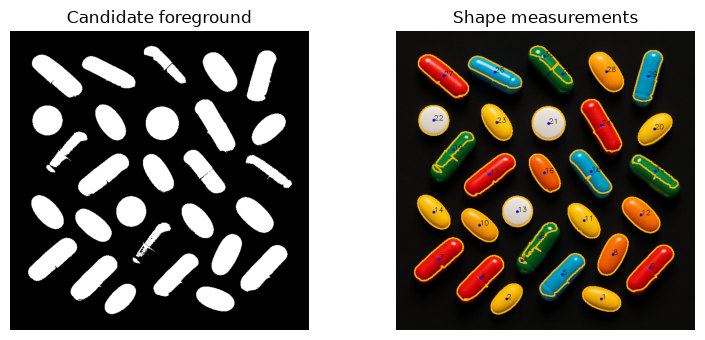

,angle_deg,area_px2,circularity,solidity,aspect_ratio,Hu1_signed_log,Hu2_signed_log
0,0,4329.0,0.7168,0.9849,2.1765,0.6749,1.7132
1,30,4331.5,0.6215,0.9739,1.4225,0.6755,1.7165
2,60,4330.5,0.6130,0.9729,0.7030,0.6755,1.7161


In [3]:
image=load_image('pildoras2.png')
g=cv2.cvtColor(image,cv2.COLOR_BGR2HSV)[:,:,2]
_,mask=cv2.threshold(g,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
contours,table=describe_contours(mask)
display(table.round(3))
panels([mask,draw_contours(image,contours,table)],['Candidate foreground','Shape measurements'])
# Controlled rotation isolates descriptor sensitivity from real-image clutter.
base=np.zeros((200,200),np.uint8);cv2.ellipse(base,(100,100),(55,25),0,0,360,255,-1)
rows=[]
for angle in [0,30,60]:
    transform=cv2.getRotationMatrix2D((100,100),angle,1)
    rotated=cv2.warpAffine(base,transform,(200,200),flags=cv2.INTER_NEAREST)
    _,measurements=describe_contours(rotated)
    if not measurements.empty:
        row=measurements.iloc[0].to_dict();row['angle_deg']=angle;rows.append(row)
display(pd.DataFrame(rows)[['angle_deg','area_px2','circularity','solidity','aspect_ratio','Hu1_signed_log','Hu2_signed_log']].round(4))


## Robotic interpretation

Select shape features for sorting elongated and round parts. Explain the effect of touching objects, mask errors and perspective. Define acceptance thresholds from independent labeled examples rather than the same examples used to report performance.


## References

- [OpenCV: thresholding](https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html)
- [OpenCV: watershed](https://docs.opencv.org/4.13.0/d3/db4/tutorial_py_watershed.html)
- [OpenCV: contours](https://docs.opencv.org/4.x/d3/d05/tutorial_py_table_of_contents_contours.html)
